# 02 · Catchment climate

1. Catchment-average monthly series of P, T, Tmax and Tmin (area-weighted mean of the ERA5-Land cells
   inside `catchment.kml`, with `meteoraster`).
2. Units: temperature K → °C ($T_{°C} = T_K - 273.15$); precipitation from mean daily rate (m/day)
   to monthly total: $P_{mm/month} = tp \cdot 1000 \cdot n_{days}$.
3. Annual totals by hydrological year (October–September), monthly climatology, driest and wettest years.

In [12]:
import sys, json
from pathlib import Path
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data")
PROC = DATA / "processed"
PROC.mkdir(exist_ok=True)
case = json.loads((DATA / "case.json").read_text())
case

{'catchment_area_km2': 55.33,
 'latitude_deg': 38.237,
 'longitude_deg': -7.687,
 'smax_mm': 100,
 'hmax_m': 5.0,
 'hmin_m': 1.0,
 'area_fixed_km2': 0.0685,
 'irrigation_months': [6, 7, 8, 9],
 'demand_hm3_per_month': 0.02,
 'eflow_fraction': 0.1,
 'target_reliability': 0.9}

In [13]:
from epss.climate import catchment_series, kelvin_to_celsius, to_monthly_mm

kml = DATA / "catchment.kml"
era5, txn = DATA / "raw" / "era5land_monthly.nc", DATA / "raw" / "tmax_tmin.nc"
clim = pd.DataFrame({
    "p_mm": to_monthly_mm(catchment_series(era5, kml, "tp")),
    "t_c": kelvin_to_celsius(catchment_series(era5, kml, "t2m")),
    "tmax_c": kelvin_to_celsius(catchment_series(txn, kml, "tmax")),
    "tmin_c": kelvin_to_celsius(catchment_series(txn, kml, "tmin")),
})
clim.to_csv(PROC / "climate.csv")
clim.describe().round(1)

,p_mm,t_c,tmax_c,tmin_c
count,480.0,480.0,480.0,480.0
mean,43.2,17.0,22.6,12.1
std,45.1,5.9,6.9,4.7
min,0.0,7.6,11.9,2.4
25%,7.9,11.8,16.3,8.2
50%,31.7,16.1,21.3,11.5
75%,61.0,22.7,29.1,16.5
max,278.8,28.8,36.7,21.2


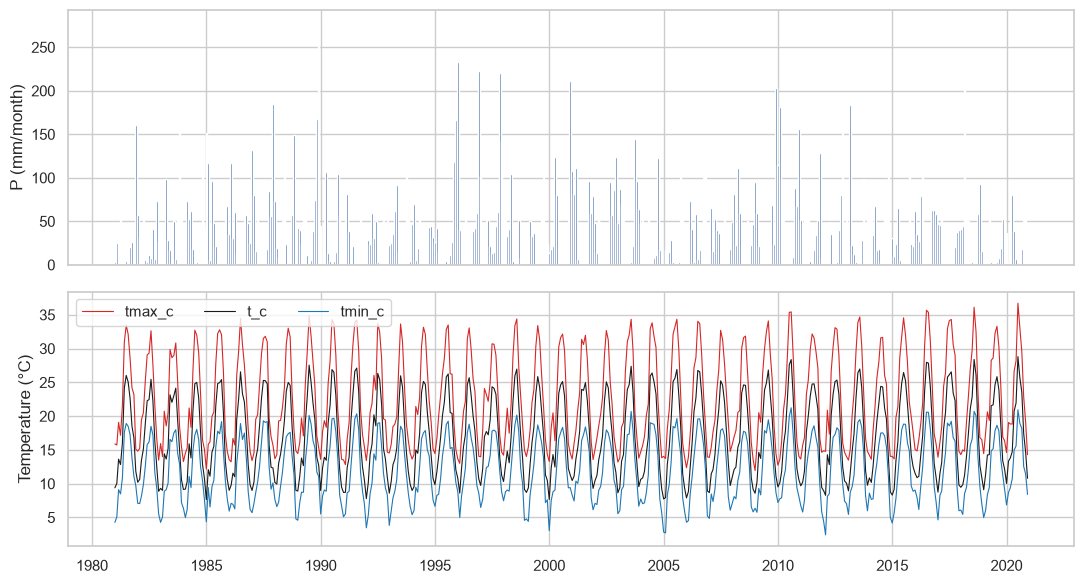

In [14]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].bar(clim.index, clim.p_mm, width=25)
ax[0].set_ylabel("P (mm/month)")
for col, color in [("tmax_c", "tab:red"), ("t_c", "k"), ("tmin_c", "tab:blue")]:
    ax[1].plot(clim.index, clim[col], color=color, lw=0.8, label=col)
ax[1].legend(ncol=3)
ax[1].set_ylabel("Temperature (°C)")
plt.tight_layout()

## Hydrological years and climatology
Use only complete hydrological years (October 1981 – September 2020). `resample("YS-OCT")` labels each
year by the October in which it starts.

In [15]:
# TODO: Annual P by hydrological year (Oct-Sep, complete years Oct 1981-Sep 2020;
#       resample('YS-OCT').sum(), index = start year) and the monthly climatology (mean by
#       calendar month).
# In: clim (DataFrame p_mm, t_c, tmax_c, tmin_c)
# Out: annual_p (pd.Series, mm/year), monthly (DataFrame, months 1-12)
# Annual P by hydrological year (Oct–Sep), only complete years
p = clim["p_mm"].loc["1981-10":"2020-09"]
annual_p = p.resample("YS-OCT").sum()
annual_p.index = annual_p.index.year          # index = start year (1981 = Oct 1981–Sep 1982)

# Monthly climatology: mean of each calendar month over all years
monthly = clim.groupby(clim.index.month).mean()
monthly.index.name = "month"

print(f"Mean annual P: {annual_p.mean():.0f} mm, CV = {annual_p.std() / annual_p.mean():.2f}")
print("Driest years:", annual_p.nsmallest(3).round(0).to_dict())
print("Wettest years:", annual_p.nlargest(3).round(0).to_dict())

Mean annual P: 520 mm, CV = 0.28
Driest years: {2004: 262.0, 1994: 288.0, 1998: 316.0}
Wettest years: {2009: 810.0, 1995: 793.0, 1997: 765.0}


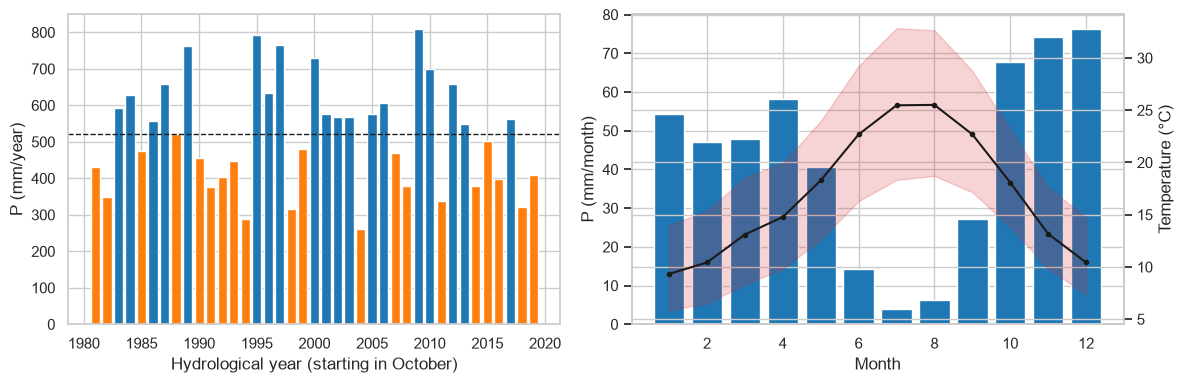

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(annual_p.index, annual_p, color=np.where(annual_p < annual_p.mean(), "tab:orange", "tab:blue"))
ax[0].axhline(annual_p.mean(), color="k", ls="--", lw=1)
ax[0].set_xlabel("Hydrological year (starting in October)"); ax[0].set_ylabel("P (mm/year)")
ax[1].bar(monthly.index, monthly.p_mm, color="tab:blue")
ax[1].set_xlabel("Month"); ax[1].set_ylabel("P (mm/month)")
ax2 = ax[1].twinx()
ax2.plot(monthly.index, monthly.t_c, "k-o", ms=3)
ax2.fill_between(monthly.index, monthly.tmin_c, monthly.tmax_c, color="tab:red", alpha=0.2)
ax2.set_ylabel("Temperature (°C)")
plt.tight_layout()

In [17]:
import seaborn as sns
import xarray as xr
import cartopy.crs as ccrs
from epss.climate import to_meteoraster, catchment_polygon

sns.set_theme(style="whitegrid", context="notebook")
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
HYD_MONTHS = MONTHS[9:] + MONTHS[:9]                        # Oct ... Sep

df = clim.copy()
df["year"], df["month"] = df.index.year, df.index.month
df["hyd_year"] = np.where(df.month >= 10, df.year, df.year - 1)
df["season"] = df.month.map({12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
                             6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"})


/opt/anaconda3/envs/epss/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/epss/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


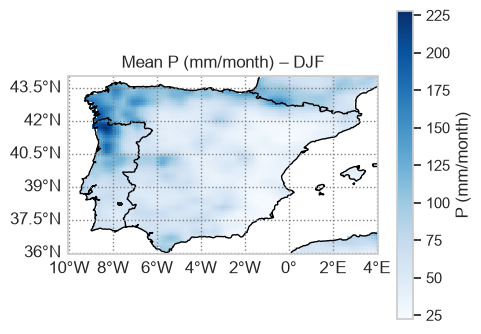

/opt/anaconda3/envs/epss/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/epss/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


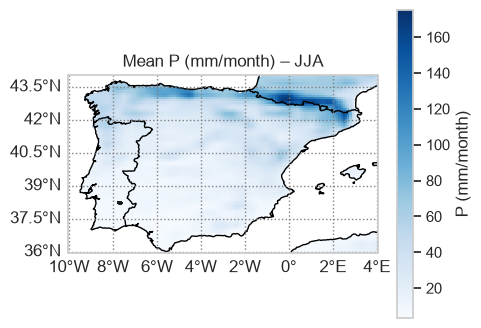

/opt/anaconda3/envs/epss/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/epss/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


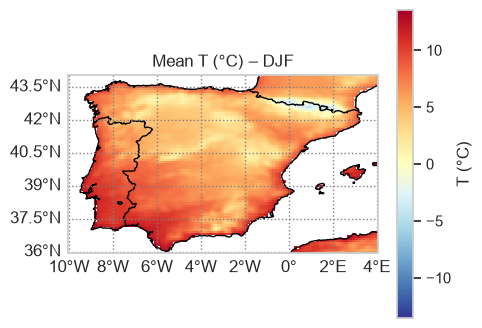

/opt/anaconda3/envs/epss/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/epss/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


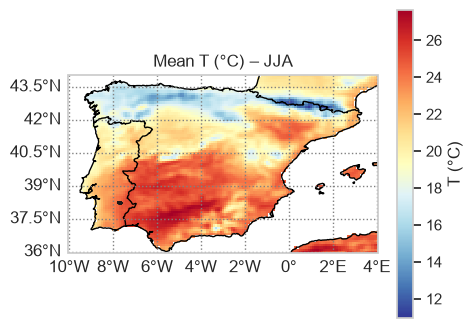

In [18]:
ds = xr.open_dataset(era5)
catchment = catchment_polygon(kml)
tp_mm = ds["tp"] * 1000 * ds["valid_time"].dt.days_in_month      # mm/month
t2m_c = ds["t2m"] - 273.15                                        # °C
season = ds["valid_time"].dt.season

panels = [(tp_mm, "DJF", "Blues",    "P (mm/month)"),
          (tp_mm, "JJA", "Blues",    "P (mm/month)"),
          (t2m_c, "DJF", "RdYlBu_r", "T (°C)"),
          (t2m_c, "JJA", "RdYlBu_r", "T (°C)")]
for da, s, cmap, label in panels:
    mr = to_meteoraster(da.where(season == s, drop=True), label, "")
    ax = mr.create_plot(central_longitude=0, figsize=(5, 4))
    ax.add_geometries(catchment, crs=ccrs.PlateCarree(), facecolor="none", edgecolor="k", linewidth=1.5)
    ax.gridlines(draw_labels=["left", "bottom"], linestyle=":", color="grey")
    ax.set_title(f"Mean {label} – {s}")
    mr.plot_mean(ax=ax, coastline=True, borders=True, colorbar_label=label, cmap=cmap, add_labels=False)


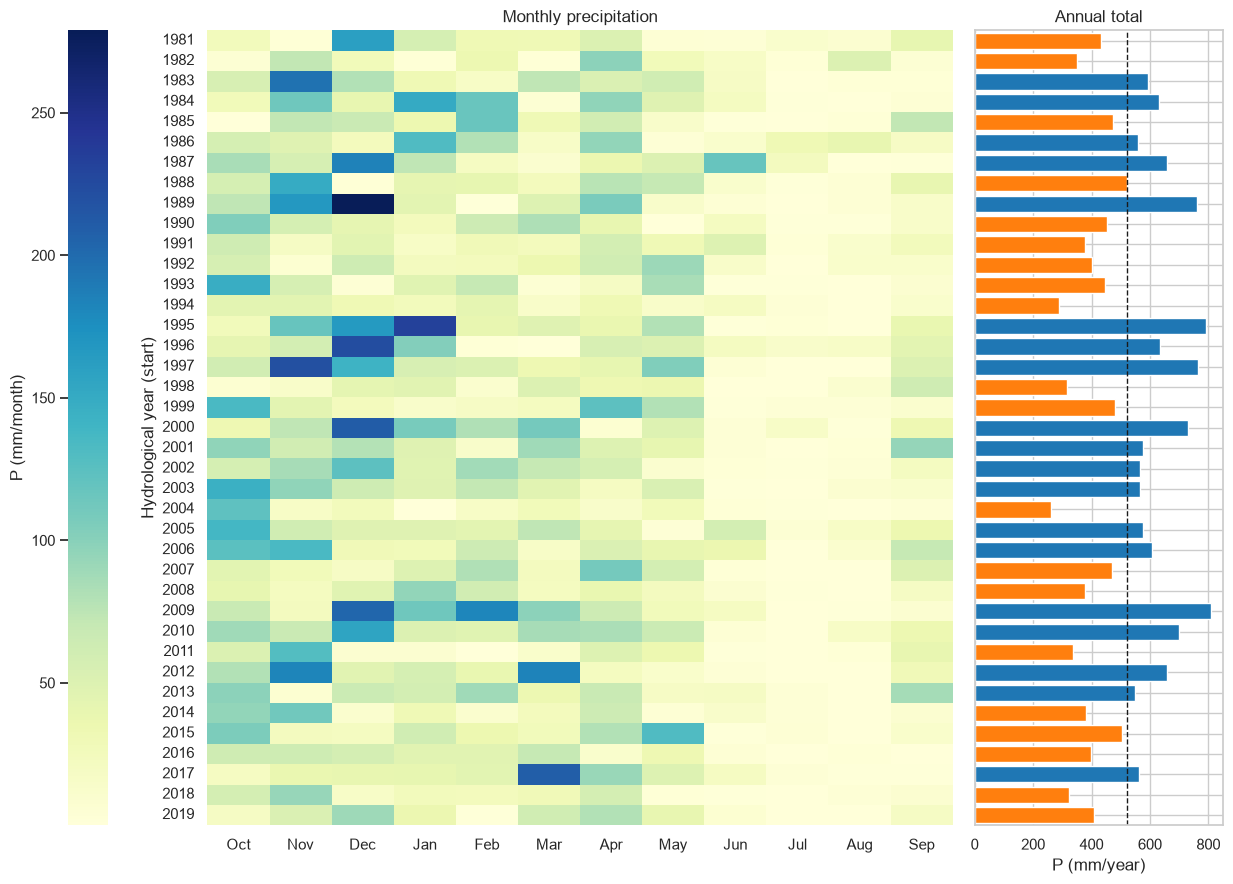

In [19]:
cal = (df.loc["1981-10":"2020-09"]
         .pivot_table(index="hyd_year", columns="month", values="p_mm")
         [[10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9]])
cal.columns = HYD_MONTHS
fig, ax = plt.subplots(1, 2, figsize=(13, 9), gridspec_kw={"width_ratios": [4, 1]}, sharey=True)
sns.heatmap(cal, cmap="YlGnBu", ax=ax[0], cbar_kws={"label": "P (mm/month)", "location": "left"})
ax[0].set(xlabel="", ylabel="Hydrological year (start)", title="Monthly precipitation")
ypos = np.arange(len(cal)) + 0.5
ax[1].barh(ypos, annual_p.loc[cal.index],
           color=np.where(annual_p.loc[cal.index] < annual_p.mean(), "tab:orange", "tab:blue"))
ax[1].axvline(annual_p.mean(), color="k", ls="--", lw=1)
ax[1].set(xlabel="P (mm/year)", title="Annual total")
plt.tight_layout(); plt.show()


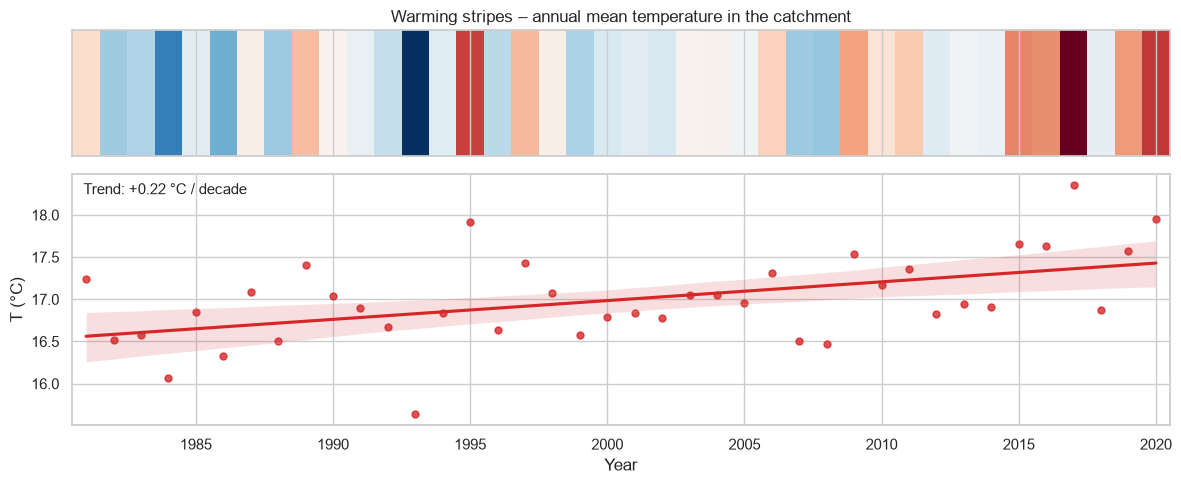

In [20]:
t_year = df.groupby("year")["t_c"].mean()
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
ax[0].imshow(t_year.values[None, :], aspect="auto", cmap="RdBu_r",
             extent=[t_year.index[0] - 0.5, t_year.index[-1] + 0.5, 0, 1])
ax[0].set_yticks([]); ax[0].set_title("Warming stripes – annual mean temperature in the catchment")
sns.regplot(x=t_year.index, y=t_year.values, ax=ax[1], color="tab:red", scatter_kws={"s": 25})
slope = np.polyfit(t_year.index, t_year.values, 1)[0]
ax[1].set(xlabel="Year", ylabel="T (°C)")
ax[1].text(0.01, 0.92, f"Trend: {slope * 10:+.2f} °C / decade", transform=ax[1].transAxes, fontsize=11)
plt.tight_layout(); plt.show()


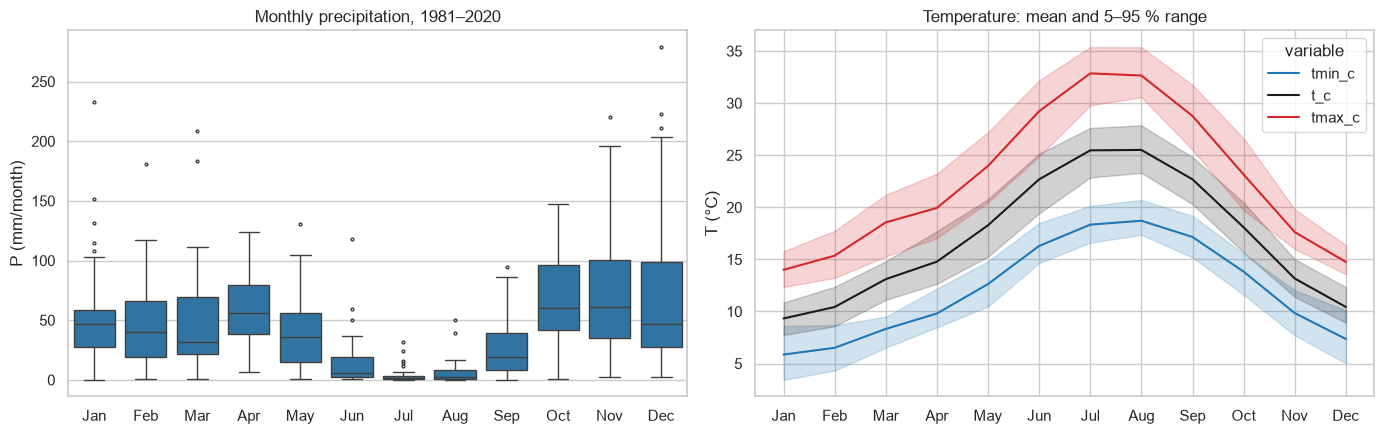

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x="month", y="p_mm", ax=ax[0], color="tab:blue", fliersize=2)
ax[0].set(xticks=range(12), xticklabels=MONTHS, xlabel="", ylabel="P (mm/month)",
          title="Monthly precipitation, 1981–2020")
long = df.melt(id_vars="month", value_vars=["tmin_c", "t_c", "tmax_c"], var_name="variable", value_name="T")
sns.lineplot(data=long, x="month", y="T", hue="variable", ax=ax[1], errorbar=("pi", 90),
             palette={"tmin_c": "tab:blue", "t_c": "k", "tmax_c": "tab:red"})
ax[1].set(xticks=range(1, 13), xticklabels=MONTHS, xlabel="", ylabel="T (°C)",
          title="Temperature: mean and 5–95 % range")
plt.tight_layout(); plt.show()


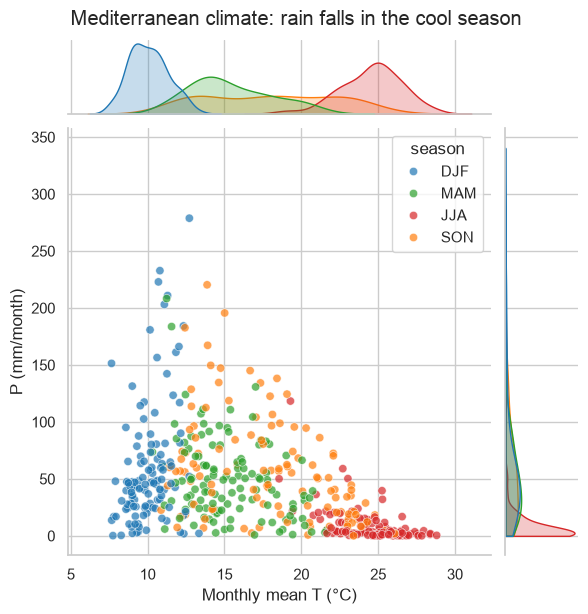

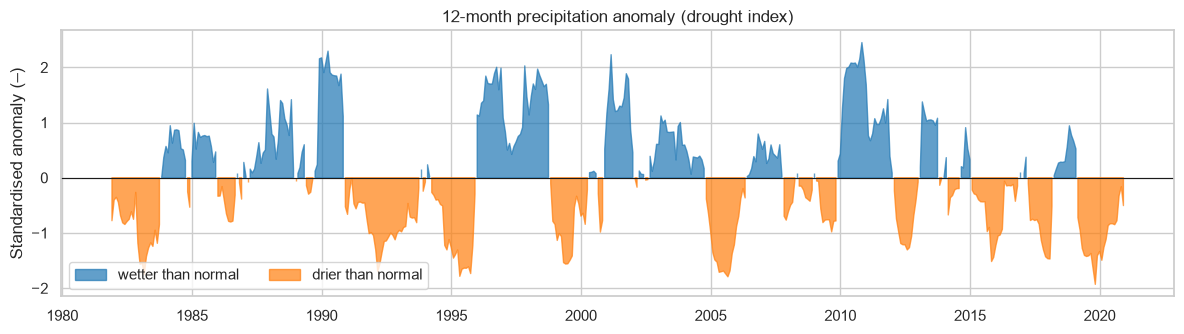

In [22]:
g = sns.jointplot(data=df, x="t_c", y="p_mm", hue="season", height=6, alpha=0.7,
                  hue_order=["DJF", "MAM", "JJA", "SON"],
                  palette={"DJF": "tab:blue", "MAM": "tab:green", "JJA": "tab:red", "SON": "tab:orange"},
                  marginal_kws={"clip": (0, None), "fill": True})
g.set_axis_labels("Monthly mean T (°C)", "P (mm/month)")
g.figure.suptitle("Mediterranean climate: rain falls in the cool season", y=1.02)
plt.show()

roll = clim["p_mm"].rolling(12).sum()
anom = (roll - roll.mean()) / roll.std()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.fill_between(anom.index, anom, 0, where=anom >= 0, color="tab:blue", alpha=0.7, label="wetter than normal")
ax.fill_between(anom.index, anom, 0, where=anom < 0, color="tab:orange", alpha=0.7, label="drier than normal")
ax.axhline(0, color="k", lw=0.8)
ax.set(ylabel="Standardised anomaly (–)", title="12-month precipitation anomaly (drought index)")
ax.legend(loc="lower left", ncol=2)
plt.tight_layout(); plt.show()


**Answer.**

What the plots show:

**Maps:** winter (DJF) rain is several times summer (JJA) rain, and summer is much hotter inland than at the coast.

**Calendar:** almost all rain falls between October and April. Some years are very wet, like 1989 and 2009, and some very dry, like 2004.

**Warming stripes:** the catchment has warmed by about +0.22 °C per decade since 1981.

**Boxplots:** July and August are almost completely dry, while rain in November and December varies a lot from year to year.

**P against T:** a typical Mediterranean pattern, with the cool months wet and the hot months dry.

**Drought index:** the dry periods stand out, for example 2004–05 and 2015-17.